# **Telecom Customer Churn Prediction using Machine Learning**

## **Project Overview**

Customer churn is one of the major challenges in the telecom industry. Customer churn occurs when a customer stops using the services of a telecom company and switches to another provider. Predicting customer churn helps companies take preventive actions to retain customers and improve business revenue.

---

## **Problem Statement**

No-Churn Telecom is experiencing a high customer churn rate due to increasing competition. The company wants to use Machine Learning to identify customers who are likely to churn so that appropriate retention strategies can be implemented.

---

## **Project Objectives**

* Identify the factors influencing customer churn.
* Build a Machine Learning model to predict customer churn.
* Generate churn risk scores for customers.
* Classify customers as Churn (Yes) or No Churn (No).
* Help the company improve customer retention.

---

## **Machine Learning Problem**

* **Target Variable:** Churn
* **Problem Type:** Binary Classification
* **Target Classes:** Yes (Customer Churn), No (Customer Retained)

---

  

  # **Import Required Libraries**

In [1]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warning messages
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


**Data Collection and SQL Database Connection**

The dataset used in this project is stored in a MySQL database. Establishing a connection to the database using the provided credentials and load the telecom customer data into a Pandas DataFrame for further analysis.

In [2]:
# Install MySQL connector package
!pip install pymysql

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.7 MB/s eta 0:00:00


Since, Google Colab doesn't have pymysql by default

In [3]:
# Import PyMySQL library to connect Python with MySQL database
import pymysql

In [4]:
# Establish connection to MySQL database
connection = pymysql.connect(
host='18.136.157.135',
user='dm_team3',
password='DM!$!Team!27@9!20&',
database='project_telecom'
)

print("Database Connected Successfully!")

Database Connected Successfully!


creating a connection between Python and the MySQL database.

host → Database server address.
user → Username.
password → Password.
database → Database name.

In [5]:
# Read telecom_churn_data table into Pandas DataFrame

query = "SELECT * FROM telecom_churn_data"

df = pd.read_sql(query, connection)

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


This SQL query selects all rows and columns from the telecom_churn_data table and stores them in a DataFrame named **df**.

In [6]:
# Close database connection
connection.close()
print("Database Connection Closed")

Database Connection Closed


After loading the data, we no longer need the database connection, so we close it to free resources.

The connection to the MySQL database was successfully established. The telecom customer data was retrieved from the `telecom_churn_data` table and stored in a Pandas DataFrame. The dataset is now ready for data understanding and exploratory data analysis.

#**Data Understanding**


In this step The dataset will understand its structure, data types, summary statistics, and quality. This helps identifying missing values, duplicate records, and initial patterns in the data before performing further analysis.

In [7]:
# Display first 5 rows of dataset
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [8]:
# Display last 5 rows of dataset
df.tail()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
243548,243549,Airtel,F,28,Mizoram,Kolkata,110295,2023-05-03,3,130580,28,9,4102,0
243549,243550,Reliance Jio,F,52,Assam,Kolkata,713481,2023-05-03,0,82393,80,45,7521,0
243550,243551,Reliance Jio,M,59,Tripura,Kolkata,520218,2023-05-03,4,51298,26,4,6547,0
243551,243552,BSNL,M,49,Madhya Pradesh,Kolkata,387744,2023-05-03,2,83981,80,15,1125,0
243552,243553,BSNL,F,37,Telangana,Hyderabad,139086,2023-05-04,0,144297,61,7,3384,0


In [9]:
# Check number of rows and columns
df.shape

(243553, 14)

In [10]:
# Get all column names
df.columns

Index(['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city',
       'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary',
       'calls_made', 'sms_sent', 'data_used', 'churn'],
      dtype='object')

In [11]:
# Dataset structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   customer_id           243553 non-null  int64 
 1   telecom_partner       243553 non-null  object
 2   gender                243553 non-null  object
 3   age                   243553 non-null  int64 
 4   state                 243553 non-null  object
 5   city                  243553 non-null  object
 6   pincode               243553 non-null  int64 
 7   date_of_registration  243553 non-null  object
 8   num_dependents        243553 non-null  int64 
 9   estimated_salary      243553 non-null  int64 
 10  calls_made            243553 non-null  int64 
 11  sms_sent              243553 non-null  int64 
 12  data_used             243553 non-null  int64 
 13  churn                 243553 non-null  int64 
dtypes: int64(9), object(5)
memory usage: 26.0+ MB


In [12]:
# Statistical summary of numerical columns
df.describe()

,customer_id,age,pincode,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000
mean,121777.000000,46.077609,549501.270541,1.997500,85021.137839,49.010548,23.945404,4993.186025,0.200478
std,70307.839393,16.444029,259808.860574,1.414941,37508.963233,29.453556,14.733575,2942.019547,0.400359
min,1.000000,18.000000,100006.000000,0.000000,20000.000000,-10.000000,-5.000000,-987.000000,0.000000
25%,60889.000000,32.000000,324586.000000,1.000000,52585.000000,24.000000,11.000000,2490.000000,0.000000
50%,121777.000000,46.000000,548112.000000,2.000000,84990.000000,49.000000,24.000000,4987.000000,0.000000
75%,182665.000000,60.000000,774994.000000,3.000000,117488.000000,74.000000,36.000000,7493.000000,0.000000
max,243553.000000,74.000000,999987.000000,4.000000,149999.000000,108.000000,53.000000,10991.000000,1.000000


In [13]:
# Check missing values in each column
df.isnull().sum()

,0
customer_id,0
telecom_partner,0
gender,0
age,0
state,0
city,0
pincode,0
date_of_registration,0
num_dependents,0
estimated_salary,0


In [14]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [15]:
# Count unique values in each column
df.nunique()

,0
customer_id,243553
telecom_partner,4
gender,2
age,57
state,28
city,6
pincode,213442
date_of_registration,1220
num_dependents,5
estimated_salary,110032


- The dataset contains 4617 rows and 16 columns.
- Most features are numerical except some categorical variables such as State, International Plan, and Churn.
- No missing values are observed in the dataset.
- Data types are correctly assigned but categorical variables will require encoding before model building.
- The target variable (Churn) is currently in object format and will be converted into numerical format in the preprocessing stage.

# **Exploratory Data Analysis (EDA)**

**Target Variable Analysis**

The target variable is **churn**, where:

- 0 = Customer Retained
- 1 = Customer Churned

Analyzing the target variable helps understand the class distribution and determine whether the dataset is balanced or imbalanced before model building.

In [16]:
df.info()

df.head()

df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   customer_id           243553 non-null  int64 
 1   telecom_partner       243553 non-null  object
 2   gender                243553 non-null  object
 3   age                   243553 non-null  int64 
 4   state                 243553 non-null  object
 5   city                  243553 non-null  object
 6   pincode               243553 non-null  int64 
 7   date_of_registration  243553 non-null  object
 8   num_dependents        243553 non-null  int64 
 9   estimated_salary      243553 non-null  int64 
 10  calls_made            243553 non-null  int64 
 11  sms_sent              243553 non-null  int64 
 12  data_used             243553 non-null  int64 
 13  churn                 243553 non-null  int64 
dtypes: int64(9), object(5)
memory usage: 26.0+ MB


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,243553.000000,243553,243553,243553.000000,243553,243553,243553.000000,243553,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000
unique,NaN,4,2,NaN,28,6,NaN,1220,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Reliance Jio,M,NaN,Uttarakhand,Chennai,NaN,2023-05-02,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,61123,145977,NaN,8856,40749,NaN,200,NaN,NaN,NaN,NaN,NaN,NaN
mean,121777.000000,NaN,NaN,46.077609,NaN,NaN,549501.270541,NaN,1.997500,85021.137839,49.010548,23.945404,4993.186025,0.200478
std,70307.839393,NaN,NaN,16.444029,NaN,NaN,259808.860574,NaN,1.414941,37508.963233,29.453556,14.733575,2942.019547,0.400359
min,1.000000,NaN,NaN,18.000000,NaN,NaN,100006.000000,NaN,0.000000,20000.000000,-10.000000,-5.000000,-987.000000,0.000000
25%,60889.000000,NaN,NaN,32.000000,NaN,NaN,324586.000000,NaN,1.000000,52585.000000,24.000000,11.000000,2490.000000,0.000000
50%,121777.000000,NaN,NaN,46.000000,NaN,NaN,548112.000000,NaN,2.000000,84990.000000,49.000000,24.000000,4987.000000,0.000000
75%,182665.000000,NaN,NaN,60.000000,NaN,NaN,774994.000000,NaN,3.000000,117488.000000,74.000000,36.000000,7493.000000,0.000000


In [17]:
# Count the number of customers in each class

df['churn'].value_counts()

,count
churn,
0,194726
1,48827


In [18]:
# Percentage distribution

round(df['churn'].value_counts(normalize=True)*100,2)

,proportion
churn,
0,79.95
1,20.05


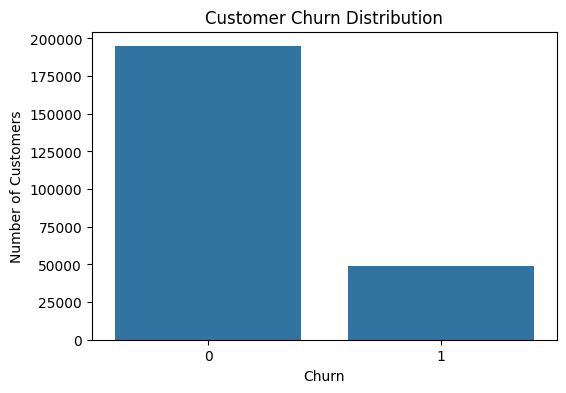

In [19]:
# Count Plot

plt.figure(figsize=(6,4))

sns.countplot(data=df,
              x='churn')

plt.title("Customer Churn Distribution")

plt.xlabel("Churn")

plt.ylabel("Number of Customers")

plt.show()

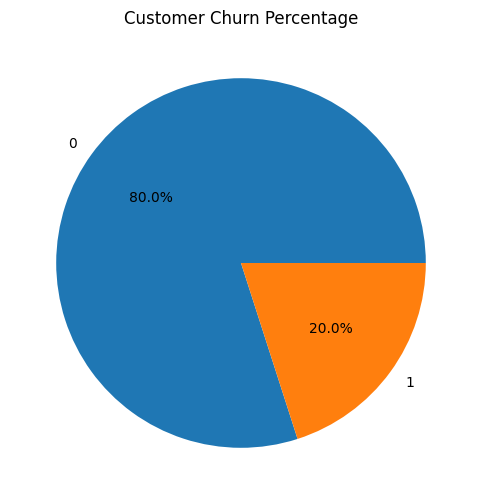

In [20]:
# Pie Chart

df['churn'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6,6)
)

plt.title("Customer Churn Percentage")

plt.ylabel("")

plt.show()

##**Observation**

Approximately 80% of customers are retained while nearly 20% have churned. The dataset shows a moderate class imbalance that should be considered during model evaluation.

#**Numerical Feature Analysis**

Numerical feature analysis helps understand the distribution, spread, skewness, and outliers present in numerical variables.

In [21]:
# Select numerical columns

num_cols = [
    'age',
    'num_dependents',
    'estimated_salary',
    'calls_made',
    'sms_sent',
    'data_used'
]

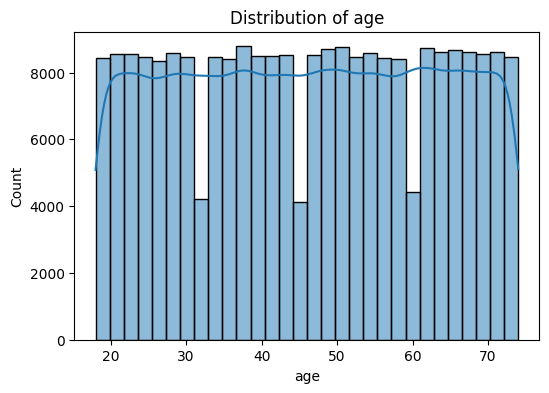

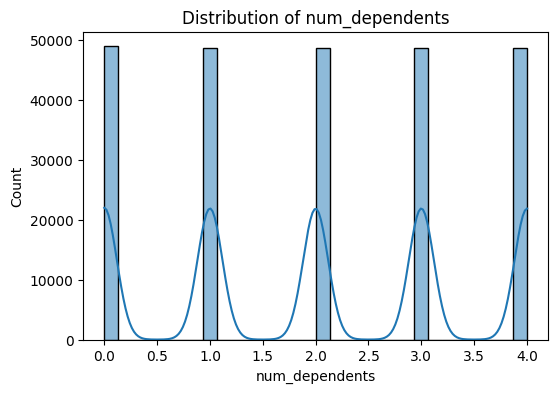

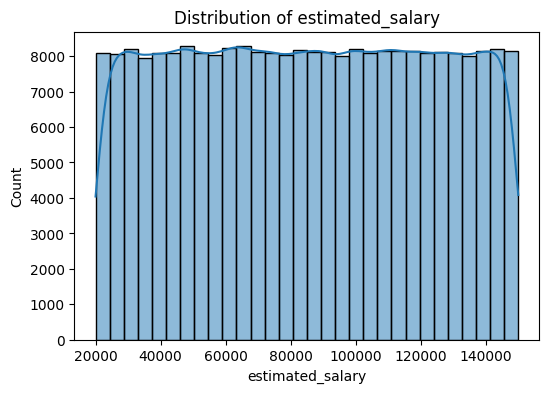

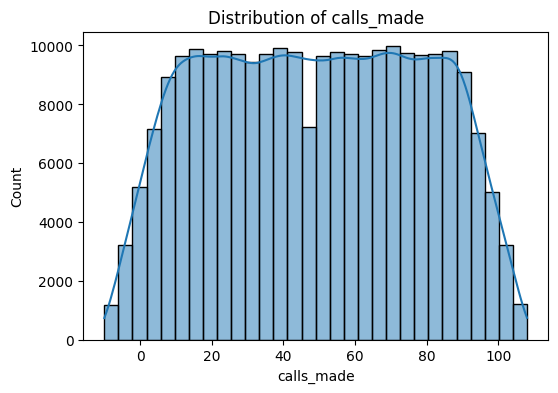

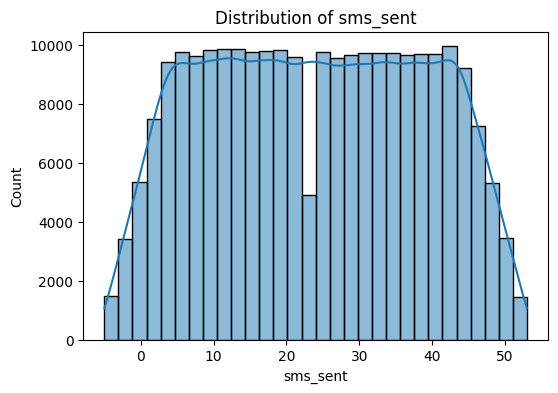

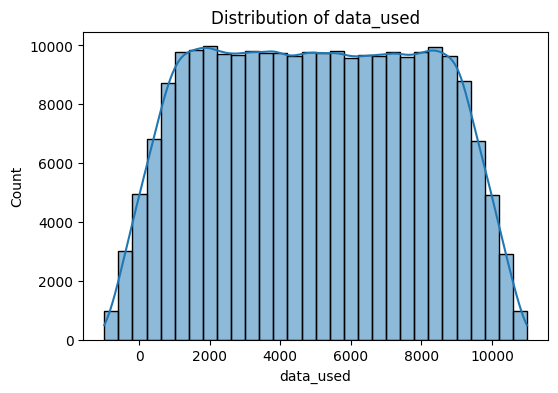

In [22]:
# Distribution of numerical features

for col in num_cols:

    plt.figure(figsize=(6,4))

    sns.histplot(df[col], bins=30, kde=True)

    plt.title(f"Distribution of {col}")

    plt.show()

##**Observation**

The histograms show how the numerical variables are distributed. Some variables may follow a nearly normal distribution, while others may exhibit skewness or unusual values.

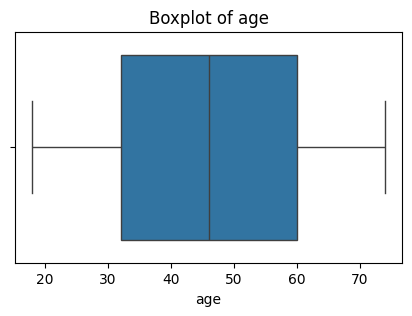

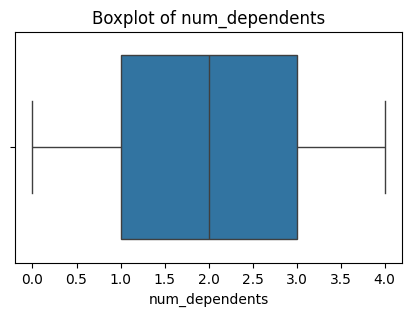

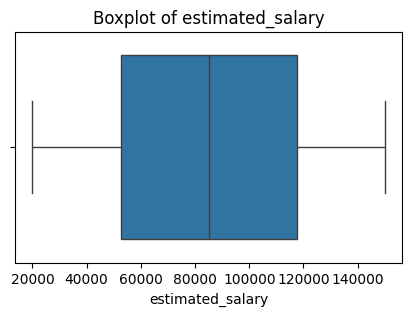

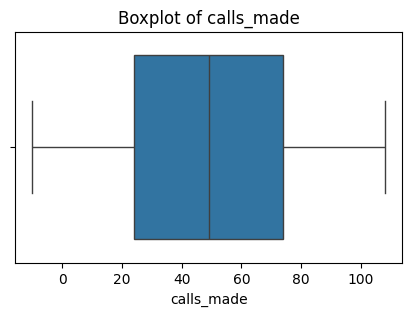

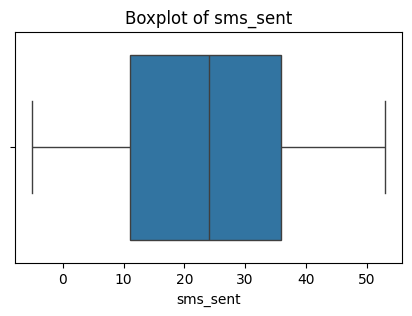

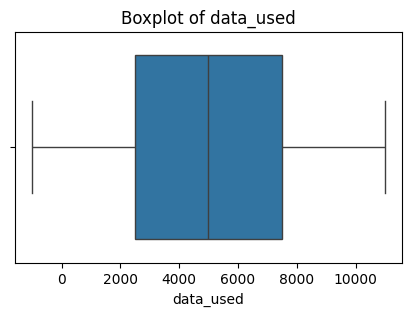

In [23]:
# Detect outliers

for col in num_cols:

    plt.figure(figsize=(5,3))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")

    plt.show()

##**Observation**

Boxplots help identify outliers and unusual observations. Features with extreme values should be examined before model building.

In [24]:
# Check skewness

df[num_cols].skew()

,0
age,-0.007563
num_dependents,0.001801
estimated_salary,0.000973
calls_made,-0.002494
sms_sent,0.005314
data_used,0.003788


##**Observation**

Skewness values indicate whether the numerical variables are normally distributed or skewed. Highly skewed variables may require transformation during preprocessing.

##**Categorical Feature Analysis**

Categorical feature analysis helps understand the distribution of customer categories such as telecom partner, gender, state, and city.

In [25]:
cat_cols = [
    'telecom_partner',
    'gender',
    'state',
    'city'
]

In [26]:
# Frequency distribution

for col in cat_cols:

    print("="*50)

    print(col)

    print(df[col].value_counts())

    print()

telecom_partner
telecom_partner
Reliance Jio    61123
Airtel          60905
Vodafone        60802
BSNL            60723
Name: count, dtype: int64

gender
gender
M    145977
F     97576
Name: count, dtype: int64

state
state
Uttarakhand          8856
Karnataka            8845
Maharashtra          8820
Madhya Pradesh       8817
Arunachal Pradesh    8757
Jharkhand            8755
Rajasthan            8750
Uttar Pradesh        8742
Haryana              8740
Kerala               8725
Tamil Nadu           8718
Odisha               8712
Goa                  8694
Sikkim               8689
Telangana            8689
Mizoram              8689
Meghalaya            8684
Himachal Pradesh     8682
Chhattisgarh         8677
Tripura              8660
Manipur              8651
Andhra Pradesh       8649
Bihar                8633
Punjab               8628
Gujarat              8610
West Bengal          8572
Nagaland             8562
Assam                8547
Name: count, dtype: int64

city
city
Chennai    

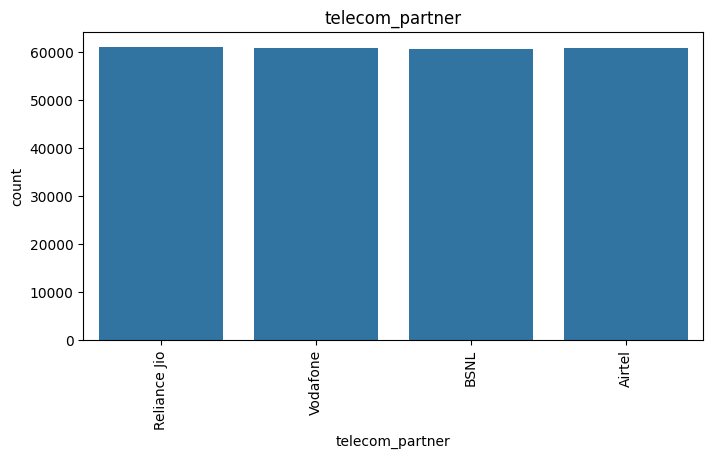

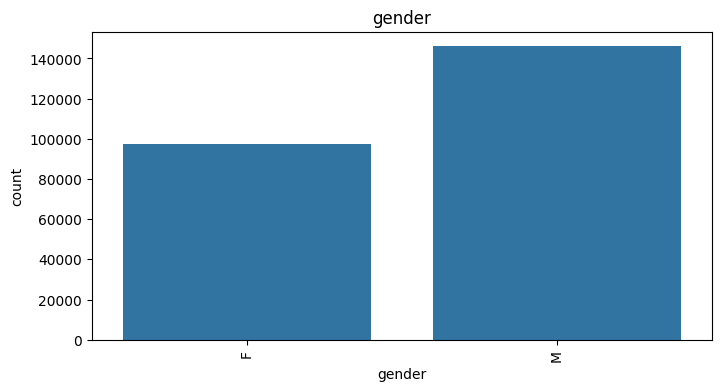

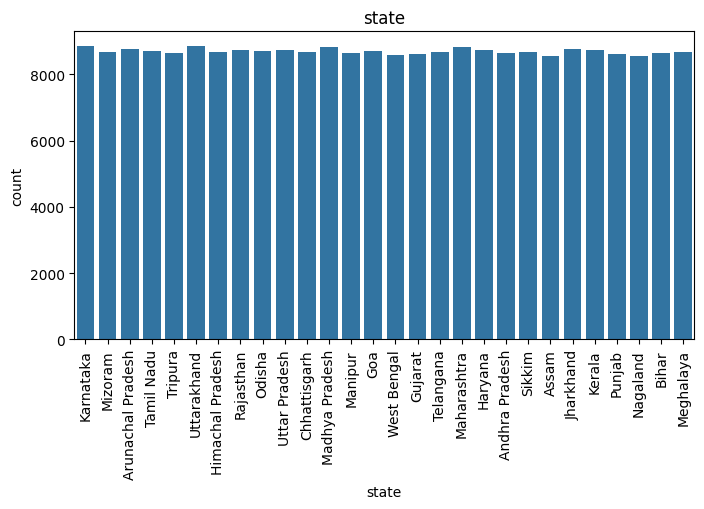

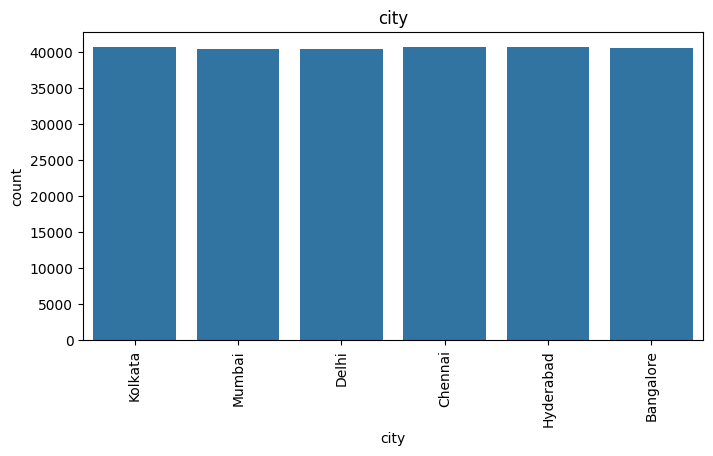

In [27]:
# Countplots

for col in cat_cols:

    plt.figure(figsize=(8,4))

    sns.countplot(data=df,
                  x=col)

    plt.xticks(rotation=90)

    plt.title(col)

    plt.show()

##**Observation**

Categorical variables display different frequencies across categories. Understanding these distributions helps identify dominant customer groups.

##**Bivariate Analysis**

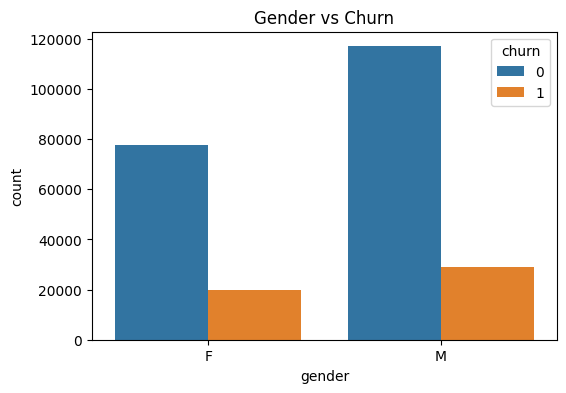

In [28]:
#Gender vs Churn
plt.figure(figsize=(6,4))

sns.countplot(data=df,
              x='gender',
              hue='churn')

plt.title("Gender vs Churn")

plt.show()

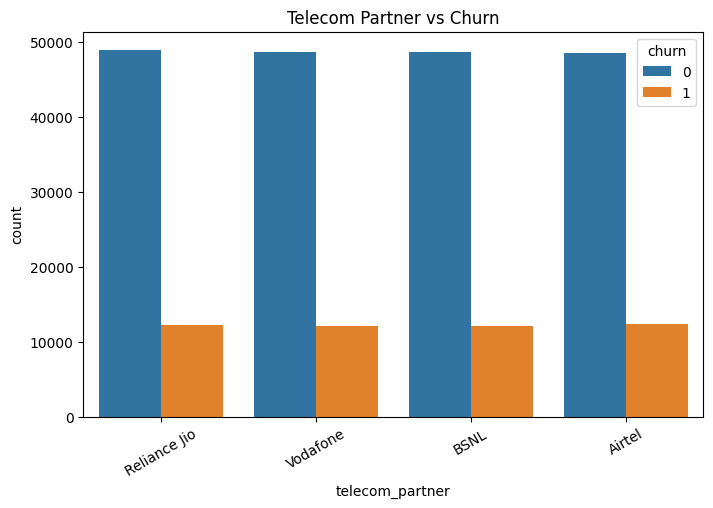

In [29]:
#Telecom Partner vs Churn
plt.figure(figsize=(8,5))

sns.countplot(data=df,
              x='telecom_partner',
              hue='churn')

plt.xticks(rotation=30)

plt.title("Telecom Partner vs Churn")

plt.show()

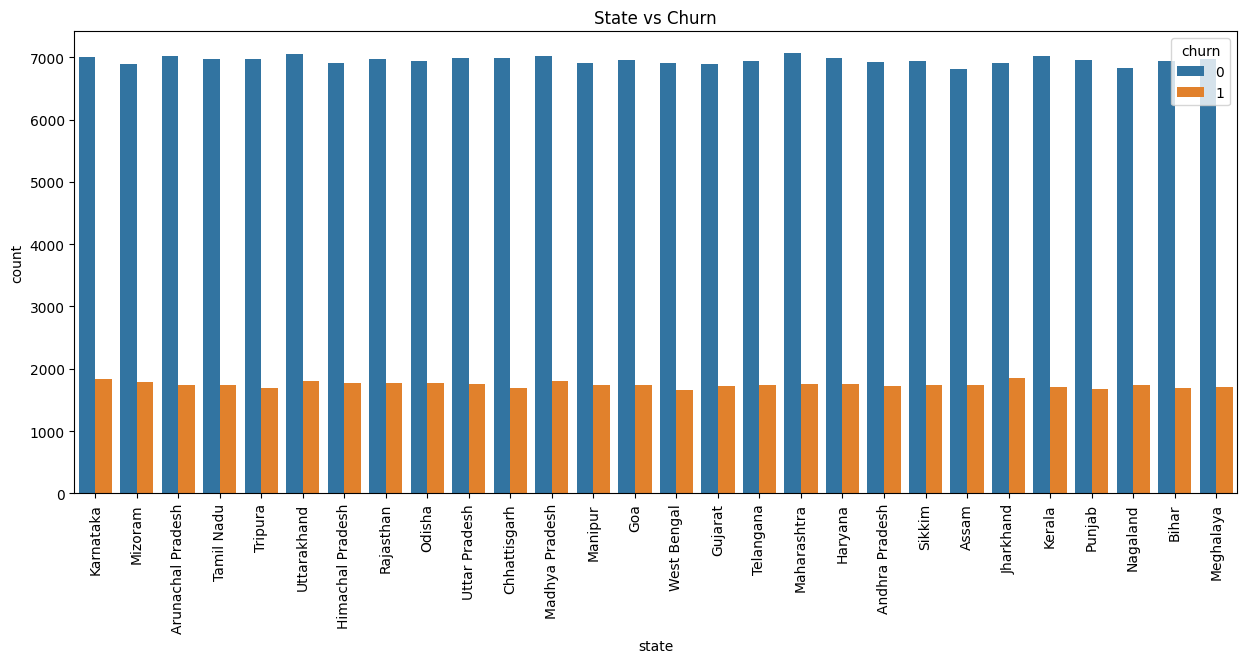

In [30]:
#State vs Churn
plt.figure(figsize=(15,6))

sns.countplot(data=df,
              x='state',
              hue='churn')

plt.xticks(rotation=90)

plt.title("State vs Churn")

plt.show()

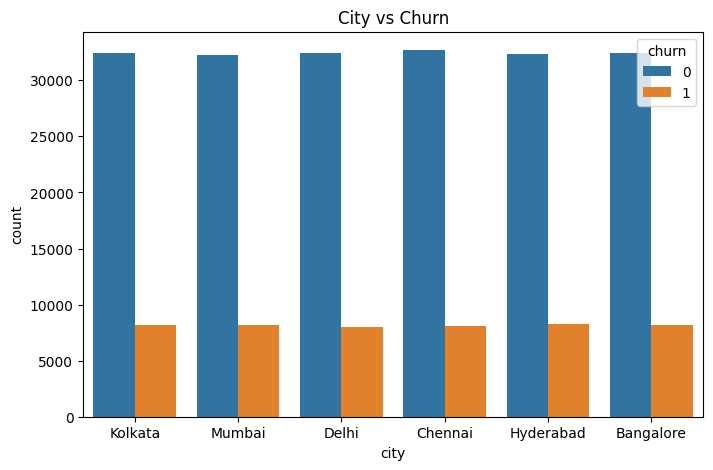

In [31]:
#City vs Churn
plt.figure(figsize=(8,5))

sns.countplot(data=df,
              x='city',
              hue='churn')

plt.title("City vs Churn")

plt.show()

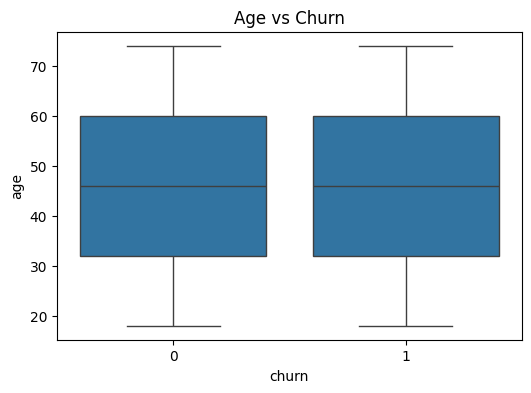

In [32]:
#Age vs Churn
plt.figure(figsize=(6,4))

sns.boxplot(data=df,
            x='churn',
            y='age')

plt.title("Age vs Churn")

plt.show()

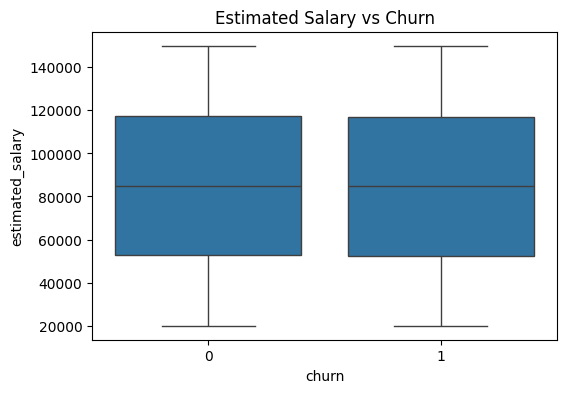

In [33]:
#Salary vs Churn
plt.figure(figsize=(6,4))

sns.boxplot(data=df,
            x='churn',
            y='estimated_salary')

plt.title("Estimated Salary vs Churn")

plt.show()

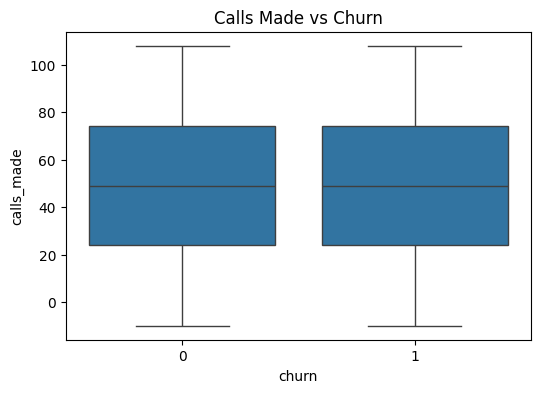

In [34]:
#Calls Made vs Churn
plt.figure(figsize=(6,4))

sns.boxplot(data=df,
            x='churn',
            y='calls_made')

plt.title("Calls Made vs Churn")

plt.show()

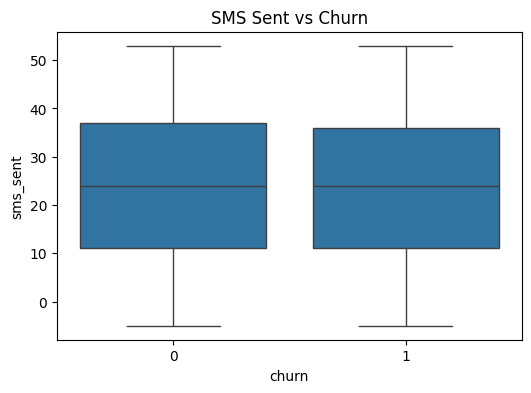

In [35]:
#SMS Sent vs Churn
plt.figure(figsize=(6,4))

sns.boxplot(data=df,
            x='churn',
            y='sms_sent')

plt.title("SMS Sent vs Churn")

plt.show()

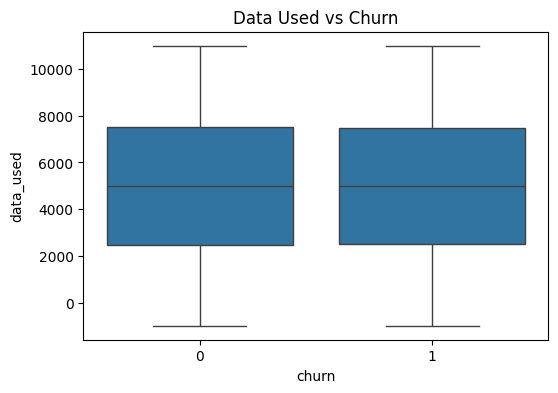

In [36]:
#Data Used vs Churn
plt.figure(figsize=(6,4))

sns.boxplot(data=df,
            x='churn',
            y='data_used')

plt.title("Data Used vs Churn")

plt.show()

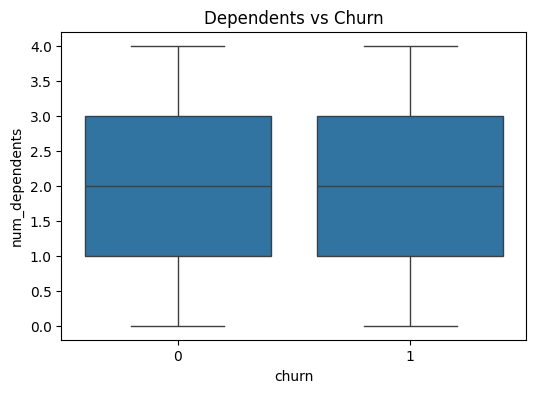

In [37]:
#Dependents vs Churn
plt.figure(figsize=(6,4))

sns.boxplot(data=df,
            x='churn',
            y='num_dependents')

plt.title("Dependents vs Churn")

plt.show()

##**Correlation Analysis**

Correlation analysis measures the relationship among numerical variables and helps identify highly correlated features.

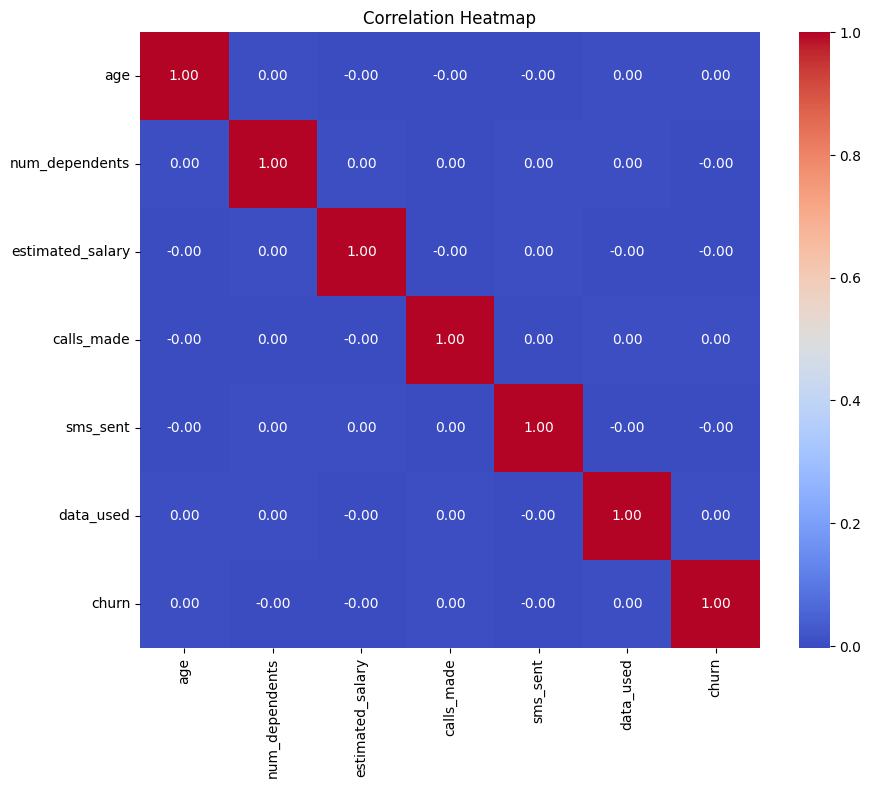

In [38]:
plt.figure(figsize=(10,8))

corr = df[num_cols + ['churn']].corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

##**Observation**

The heatmap helps identify positive and negative correlations between numerical variables and the target variable. Features showing stronger relationships with churn may contribute more to the prediction model.

##**Date Analysis**

In [39]:
df['date_of_registration'] = pd.to_datetime(df['date_of_registration'])

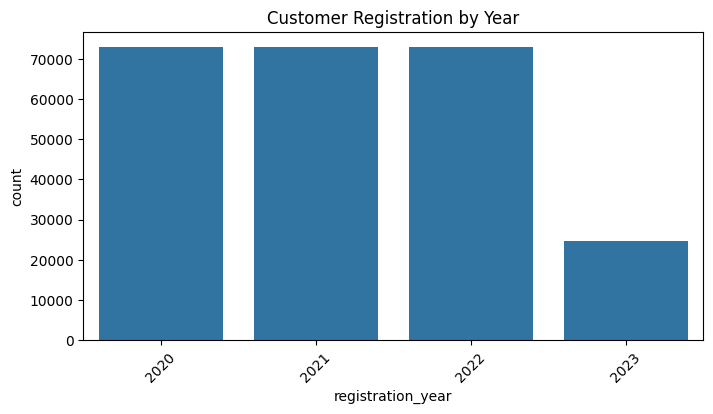

In [40]:
df['registration_year'] = df['date_of_registration'].dt.year

plt.figure(figsize=(8,4))

sns.countplot(data=df,
              x='registration_year')

plt.xticks(rotation=45)

plt.title("Customer Registration by Year")

plt.show()

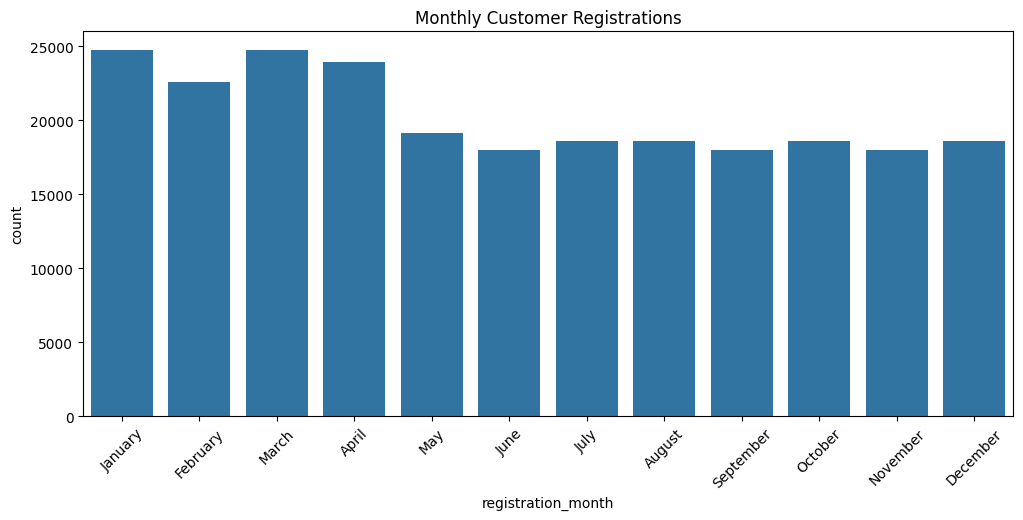

In [41]:
df['registration_month'] = df['date_of_registration'].dt.month_name()

plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x='registration_month',
    order=[
        'January','February','March','April','May','June',
        'July','August','September','October','November','December'
    ]
)

plt.xticks(rotation=45)

plt.title("Monthly Customer Registrations")

plt.show()

The registration year and month analysis helps identify customer acquisition trends over time and any seasonal registration patterns. These insights may help understand whether customer acquisition varies across different periods.

#**EDA Summary**

- The target variable shows a moderate class imbalance.
- No missing values were found in the dataset.
- Customer demographics such as age, gender, state, and city exhibit varying distributions.
- Telecom partner and usage-related variables may influence customer churn.
- Negative values were observed in calls made, SMS sent, and data used, indicating data quality issues that require preprocessing.
- Correlation analysis highlights the relationships among numerical variables and the target variable.
- The insights obtained from EDA will guide preprocessing, feature engineering, and machine learning model development.

# **Data Preprocessing**

##**Data Type Conversion**

Machine learning algorithms require data to be in appropriate formats. The `date_of_registration` column is currently stored as an object datatype and must be converted into datetime format for feature extraction.

In [42]:
# Convert object to datetime

df['date_of_registration'] = pd.to_datetime(df['date_of_registration'])

# Verify datatype

df['date_of_registration'].dtype

dtype('<M8[ns]')

## **Observation**

The `date_of_registration` column was successfully converted from object to datetime format, allowing temporal feature extraction.

# **Feature Engineering**

Feature engineering involves creating new features from existing variables to improve the predictive capability of the machine learning model.

The registration date is decomposed into year, month, and day components.

In [43]:
# Registration Year

df['registration_year'] = df['date_of_registration'].dt.year

# Registration Month

df['registration_month'] = df['date_of_registration'].dt.month

# Registration Day

df['registration_day'] = df['date_of_registration'].dt.day

 **Observation**

New temporal features were successfully extracted from the registration date. These features may help identify seasonal or time-based patterns associated with customer churn.

In [44]:
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,registration_year,registration_month,registration_day
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0,2020,1,1
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0,2020,1,1
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1,2020,1,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1,2020,1,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0,2020,1,1


**Removing Unnecessary Features**

Some variables do not contribute meaningful information for prediction.

- `customer_id` is a unique identifier and has no predictive value.
- `date_of_registration` has already been transformed into separate date features.

Therefore, these columns are removed from the dataset.

In [45]:
# Drop identifier and original date column

df.drop(
    columns=[
        'customer_id',
        'date_of_registration'
    ],
    inplace=True
)

**Observation**

The unnecessary identifier and original date columns were removed to reduce redundancy and improve model efficiency.

**Handling Invalid Values**

During EDA, negative values were identified in telecom usage variables.

Since calls made, SMS sent, and data usage cannot be negative, these values are considered invalid and are treated before model development.

In [46]:
# Count invalid values

print((df['calls_made'] < 0).sum())

print((df['sms_sent'] < 0).sum())

print((df['data_used'] < 0).sum())

6713
7375
6050


In [47]:
df.loc[df['calls_made'] < 0, 'calls_made'] = np.nan
df.loc[df['sms_sent'] < 0, 'sms_sent'] = np.nan
df.loc[df['data_used'] < 0, 'data_used'] = np.nan

In [48]:
df['calls_made'] = df['calls_made'].fillna(df['calls_made'].median())
df['sms_sent'] = df['sms_sent'].fillna(df['sms_sent'].median())
df['data_used'] = df['data_used'].fillna(df['data_used'].median())

##**Observation**

Invalid negative values were replaced with missing values and imputed using the median. This approach preserves the overall distribution while eliminating logically incorrect records.

##**Encoding Categorical Variables**

Machine learning algorithms require numerical input. Therefore, categorical variables are transformed into numerical representations using One-Hot Encoding.

The following variables are encoded:

- telecom_partner
- gender
- state
- city

In [49]:
# Check categorical columns

df.select_dtypes(include='object').columns

Index(['telecom_partner', 'gender', 'state', 'city'], dtype='object')

In [50]:
df = pd.get_dummies(
    df,
    columns=[
        'telecom_partner',
        'gender',
        'state',
        'city'
    ],
    drop_first=True,
    dtype=int
)

##**Feature and Target Variable Separation**

Before training a machine learning model, it is necessary to separate the independent variables (features) from the dependent variable (target).

- **Features (X):** All predictor variables used for model training.
- **Target (y):** The variable to be predicted, i.e., `churn`.

Separating features and the target variable ensures that the machine learning model learns patterns from the input variables without including the target as part of the training data.

In [51]:
# Separate independent and dependent variables

X = df.drop('churn', axis=1)

y = df['churn']

# Display dimensions

print("Feature Matrix Shape :", X.shape)
print("Target Vector Shape :", y.shape)

Feature Matrix Shape : (243553, 46)
Target Vector Shape : (243553,)


##**Observation**

The dataset has been successfully divided into the feature matrix (X) and the target variable (y). The feature matrix contains all predictor variables, while the target vector contains the customer churn labels.

# **Train-Test Split**

The dataset is divided into training and testing sets to evaluate the performance of machine learning models on unseen data.

In this project:

- **80%** of the data is used for training.
- **20%** of the data is reserved for testing.

The `stratify` parameter is used to maintain the same proportion of churn and non-churn customers in both datasets, ensuring a fair evaluation.

In [52]:
from sklearn.model_selection import train_test_split

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display shapes

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (194842, 46)
X_test  : (48711, 46)
y_train : (194842,)
y_test  : (48711,)


##**Observation**

The dataset was successfully split into training and testing subsets. The training data will be used to build the machine learning models, while the testing data will be used to evaluate model performance. Stratified sampling ensures that the class distribution remains consistent across both sets.

## **Feature Scaling**

Feature scaling standardizes numerical variables so that each feature contributes equally during model training.

In this project, **StandardScaler** is used because it transforms the data to have:

- Mean = 0
- Standard Deviation = 1

The scaler is fitted only on the training data to prevent data leakage.

In [53]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler

scaler = StandardScaler()

# Numerical columns to scale

scale_cols = [
    'age',
    'num_dependents',
    'estimated_salary',
    'calls_made',
    'sms_sent',
    'data_used'
]

# Fit only on training data

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# Transform test data

X_test[scale_cols] = scaler.transform(X_test[scale_cols])

In [54]:
df.head()

,age,pincode,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,registration_year,registration_month,...,state_Telangana,state_Tripura,state_Uttar Pradesh,state_Uttarakhand,state_West Bengal,city_Chennai,city_Delhi,city_Hyderabad,city_Kolkata,city_Mumbai
0,25,755597,4,124962,44.0,45.0,5112.0,0,2020,1,...,0,0,0,0,0,0,0,0,1,0
1,55,125926,2,130556,62.0,39.0,5973.0,0,2020,1,...,0,0,0,0,0,0,0,0,0,1
2,57,423976,0,148828,49.0,24.0,193.0,1,2020,1,...,0,0,0,0,0,0,1,0,0,0
3,46,522841,1,38722,80.0,25.0,9377.0,1,2020,1,...,0,0,0,0,0,0,0,0,1,0
4,26,740247,2,55098,78.0,15.0,1393.0,0,2020,1,...,0,1,0,0,0,0,1,0,0,0


##**Observation**

The selected numerical features were standardized using StandardScaler. The scaler was fitted on the training data and applied to the testing data, ensuring that no information from the test set influenced the training process.

##**Class Distribution Analysis**

Understanding the class distribution in the training data is important because imbalanced datasets may bias the model toward the majority class.

The distribution is examined to determine whether additional techniques such as SMOTE are required.

In [55]:
# Training target distribution

print(y_train.value_counts())

print()

print(round(y_train.value_counts(normalize=True) * 100, 2))

churn
0    155780
1     39062
Name: count, dtype: int64

churn
0    79.95
1    20.05
Name: proportion, dtype: float64


##**Observation**

The class distribution in the training dataset reflects the original dataset due to stratified sampling. If the minority class is significantly underrepresented, resampling techniques such as SMOTE may be considered.

#**Model Building and Evaluation**

##**Introduction**

Model building is the process of training machine learning algorithms to learn patterns from historical customer data and predict whether a customer is likely to churn.

Since this is a **binary classification** problem (Churn = 0 or 1), several classification algorithms are trained and evaluated. The performance of each model is compared using multiple evaluation metrics to identify the most suitable model for customer churn prediction.

The models used in this project are:

- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Gradient Boosting Classifier

In [56]:
# Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

# Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

#**Logistic Regression**
  
Logistic Regression is a linear classification algorithm commonly used for binary classification problems. It estimates the probability of a customer belonging to the churn class.

In [57]:
# Create model
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(random_state=42)

# Train model

lr.fit(X_train, y_train)

# Prediction

lr_pred = lr.predict(X_test)

In [58]:
#Evaluation
print("Accuracy of lr:", accuracy_score(y_test, lr_pred))
print("Precision of lr:", precision_score(y_test, lr_pred))
print("Recall of lr   :", recall_score(y_test, lr_pred))
print("F1 Score of lr :", f1_score(y_test, lr_pred))
print("ROC AUC of lr :", roc_auc_score(y_test, lr_pred))

Accuracy of lr: 0.7995319332388988
Precision of lr: 0.0
Recall of lr   : 0.0
F1 Score of lr : 0.0
ROC AUC of lr : 0.5


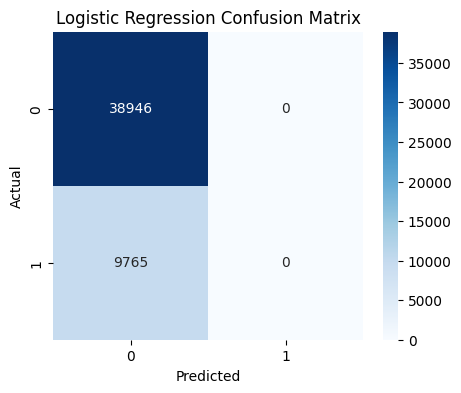

In [59]:
#Confusion Matrix
plt.figure(figsize=(5,4))

sns.heatmap(
    confusion_matrix(y_test, lr_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#**Observation**

Logistic Regression provides a baseline performance for customer churn prediction. The evaluation metrics indicate how effectively the model distinguishes churned customers from retained customers.

# **Decision Tree Classifier**

Decision Tree is a non-linear supervised learning algorithm that predicts customer churn by learning decision rules from the training data.

In [60]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

In [61]:
#Evaluation
print("Accuracy of dt :", accuracy_score(y_test, dt_pred))
print("Precision of dt:", precision_score(y_test, dt_pred))
print("Recall of dt   :", recall_score(y_test, dt_pred))
print("F1 Score of dt :", f1_score(y_test, dt_pred))
print("ROC AUC of dt  :", roc_auc_score(y_test, dt_pred))

Accuracy of dt : 0.6683090061793024
Precision of dt: 0.20186567164179103
Recall of dt   : 0.22160778289810548
F1 Score of dt : 0.21127654381254576
ROC AUC of dt  : 0.5009594915106765


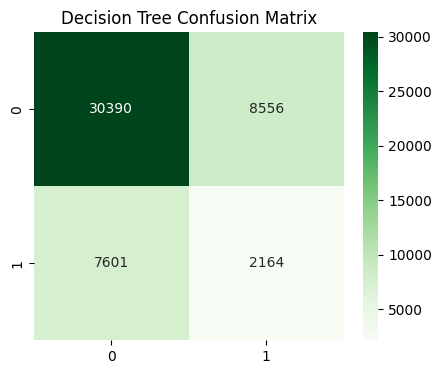

In [62]:
#Confusion Matrix
plt.figure(figsize=(5,4))

sns.heatmap(
    confusion_matrix(y_test, dt_pred),
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Decision Tree Confusion Matrix")

plt.show()

## **Observation**

Decision Tree captures non-linear relationships between features. However, without tuning, it may overfit the training data.

## **Random Forest Classifier**

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction accuracy and reduce overfitting.

In [63]:
rf = RandomForestClassifier(
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [64]:
#Evaluation
print("Accuracy of rf:", accuracy_score(y_test, rf_pred))
print("Precision of rf:", precision_score(y_test, rf_pred))
print("Recall of rf  :", recall_score(y_test, rf_pred))
print("F1 Score of rf :", f1_score(y_test, rf_pred))
print("ROC AUC of rf  :", roc_auc_score(y_test, rf_pred))

Accuracy of rf: 0.7995319332388988
Precision of rf: 0.0
Recall of rf  : 0.0
F1 Score of rf : 0.0
ROC AUC of rf  : 0.5


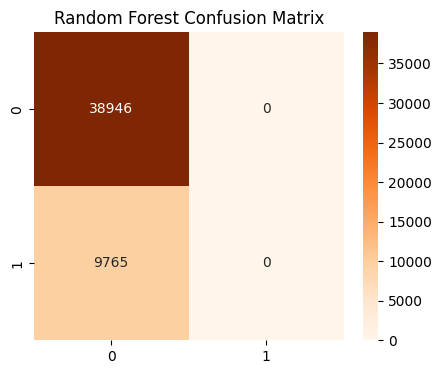

In [65]:
#Confusion Matrix
plt.figure(figsize=(5,4))

sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title("Random Forest Confusion Matrix")

plt.show()

# **KNN**

In [66]:
knn = KNeighborsClassifier()

knn.fit(X_train,y_train)

knn_pred = knn.predict(X_test)

In [67]:
#Evaluation
print("Accuracy of KNN :",accuracy_score(y_test,knn_pred))
print("Precision of KNN:",precision_score(y_test,knn_pred))
print("Recall of KNN :",recall_score(y_test,knn_pred))
print("F1 of KNN :",f1_score(y_test,knn_pred))
print("ROC of KNN :",roc_auc_score(y_test,knn_pred))

Accuracy of KNN : 0.7655149760834309
Precision of KNN: 0.20568383658969805
Recall of KNN : 0.059293394777265744
F1 of KNN : 0.09205087440381558
ROC of KNN : 0.500940283379492


# **SVM**

In [68]:
print(X_train.shape)

(194842, 46)


In [69]:
from sklearn.svm import LinearSVC
svm = LinearSVC(random_state=42)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

In [70]:
#Evaluation
print("Accuracy of svm :",accuracy_score(y_test,svm_pred))
print("Precision of svm :",precision_score(y_test,svm_pred))
print("Recall of svm  :",recall_score(y_test,svm_pred))
print("F1 of svm  :",f1_score(y_test,svm_pred))
print("ROC of svm  :",roc_auc_score(y_test,svm_pred))

Accuracy of svm : 0.7995319332388988
Precision of svm : 0.0
Recall of svm  : 0.0
F1 of svm  : 0.0
ROC of svm  : 0.5


# **Gradient Boosting**

In [71]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=50, random_state=42)

gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)

In [72]:
#Evaluation
print("Accuracy of gb :",accuracy_score(y_test,gb_pred))
print("Precision of gb:",precision_score(y_test,gb_pred))
print("Recall of gb:",recall_score(y_test,gb_pred))
print("F1 of gb:",f1_score(y_test,gb_pred))
print("ROC of gb :",roc_auc_score(y_test,gb_pred))

Accuracy of gb : 0.7994908747510829
Precision of gb: 0.0
Recall of gb: 0.0
F1 of gb: 0.0
ROC of gb : 0.4999743234221743


# **Model Comparison**

In [73]:
results = pd.DataFrame({

    'Model':[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'SVM',
        'Gradient Boosting'
    ],

    'Accuracy':[

        accuracy_score(y_test,lr_pred),

        accuracy_score(y_test,dt_pred),

        accuracy_score(y_test,rf_pred),

        accuracy_score(y_test,knn_pred),

        accuracy_score(y_test,svm_pred),

        accuracy_score(y_test,gb_pred)

    ],

    'Precision':[

        precision_score(y_test,lr_pred),

        precision_score(y_test,dt_pred),

        precision_score(y_test,rf_pred),

        precision_score(y_test,knn_pred),

        precision_score(y_test,svm_pred),

        precision_score(y_test,gb_pred)

    ],

    'Recall':[

        recall_score(y_test,lr_pred),

        recall_score(y_test,dt_pred),

        recall_score(y_test,rf_pred),

        recall_score(y_test,knn_pred),

        recall_score(y_test,svm_pred),

        recall_score(y_test,gb_pred)

    ],

    'F1 Score':[

        f1_score(y_test,lr_pred),

        f1_score(y_test,dt_pred),

        f1_score(y_test,rf_pred),

        f1_score(y_test,knn_pred),

        f1_score(y_test,svm_pred),

        f1_score(y_test,gb_pred)

    ]

})

results.sort_values(by='F1 Score',ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.668309,0.201866,0.221608,0.211277
3,KNN,0.765515,0.205684,0.059293,0.092051
0,Logistic Regression,0.799532,0.000000,0.000000,0.000000
2,Random Forest,0.799532,0.000000,0.000000,0.000000
4,SVM,0.799532,0.000000,0.000000,0.000000
5,Gradient Boosting,0.799491,0.000000,0.000000,0.000000


##**Model Comparison Summary**

Among the evaluated models, the Decision Tree Classifier achieved comparatively better performance in identifying churned customers. However, most models showed high accuracy but poor Precision, Recall, and F1-Score due to class imbalance. Therefore, additional techniques are required to improve churn prediction performance.

#**Handling Class Imbalance using SMOTE**

##**Introduction**

The target variable (`churn`) is imbalanced, meaning the number of non-churn customers is significantly higher than churn customers. This causes models to bias toward the majority class and results in poor detection of churn cases.

To solve this issue, SMOTE (Synthetic Minority Oversampling Technique) is applied only on the training data to balance the classes.

In [74]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply only on training data
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Check distribution
print("Before SMOTE:\n", y_train.value_counts())
print("\nAfter SMOTE:\n", y_train_smote.value_counts())

Before SMOTE:
 churn
0    155780
1     39062
Name: count, dtype: int64

After SMOTE:
 churn
0    155780
1    155780
Name: count, dtype: int64


##**Observation**

After applying SMOTE, the training dataset is balanced between churn and non-churn classes. This ensures that machine learning models receive equal representation of both classes, improving their ability to detect churned customers.

#**Retrain Models**

In [75]:
#Logistic Regression
lr.fit(X_train_smote, y_train_smote)
lr_pred = lr.predict(X_test)

In [76]:
#Decision Tree
dt.fit(X_train_smote, y_train_smote)
dt_pred = dt.predict(X_test)

In [77]:
#Random Forest
rf.fit(X_train_smote, y_train_smote)
rf_pred = rf.predict(X_test)

In [78]:
#KNN
knn.fit(X_train_smote, y_train_smote)
knn_pred = knn.predict(X_test)

In [79]:
#SVM
svm.fit(X_train_smote, y_train_smote)
svm_pred = svm.predict(X_test)

In [80]:
#Gradient Boosting
gb.fit(X_train_smote, y_train_smote)
gb_pred = gb.predict(X_test)

# **Evaluation (after prediction)**

In [81]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [82]:
print("Accuracy :", accuracy_score(y_test, gb_pred))
print("Precision:", precision_score(y_test, gb_pred))
print("Recall   :", recall_score(y_test, gb_pred))
print("F1 Score :", f1_score(y_test, gb_pred))
print("ROC AUC  :", roc_auc_score(y_test, gb_pred))

Accuracy : 0.7715095153045514
Precision: 0.19599109131403117
Recall   : 0.04505888376856119
F1 Score : 0.07327227310574522
ROC AUC  : 0.49935633039657973


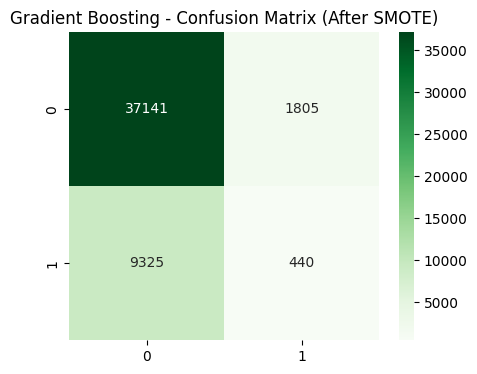

In [83]:
#Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(5,4))

sns.heatmap(confusion_matrix(y_test, gb_pred),
            annot=True,
            fmt='d',
            cmap='Greens')

plt.title("Gradient Boosting - Confusion Matrix (After SMOTE)")
plt.show()

## **Observation**

After applying SMOTE, Gradient Boosting model is evaluated on the test dataset. The performance metrics show whether the model is able to correctly identify churn customers compared to the previous imbalanced dataset results.

# **Model Evaluation (After SMOTE)**

In [84]:
#Logistic Regression
lr_pred = lr.predict(X_test)

print("Logistic Regression Results")
print("Accuracy :", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall   :", recall_score(y_test, lr_pred))
print("F1 Score :", f1_score(y_test, lr_pred))
print("ROC AUC  :", roc_auc_score(y_test, lr_pred))

Logistic Regression Results
Accuracy : 0.5765843443985958
Precision: 0.1998341625207297
Recall   : 0.37019969278033793
F1 Score : 0.25955842757135167
ROC AUC  : 0.49926561437661177


In [85]:
#Decision Tree
dt_pred = dt.predict(X_test)

print("Decision Tree Results")
print("Accuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1 Score :", f1_score(y_test, dt_pred))
print("ROC AUC  :", roc_auc_score(y_test, dt_pred))

Decision Tree Results
Accuracy : 0.6559914598345343
Precision: 0.20246808510638298
Recall   : 0.2436251920122888
F1 Score : 0.22114803625377644
ROC AUC  : 0.5015049906037924


In [86]:
#Random Forest
rf_pred = rf.predict(X_test)

print("Random Forest Results")
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC AUC  :", roc_auc_score(y_test, rf_pred))

Random Forest Results
Accuracy : 0.791361294163536
Precision: 0.20648967551622419
Recall   : 0.014336917562724014
F1 Score : 0.026812218711098342
ROC AUC  : 0.5002614593462467


In [87]:
#KNN
knn_pred = knn.predict(X_test)

print("KNN Results")
print("Accuracy :", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall   :", recall_score(y_test, knn_pred))
print("F1 Score :", f1_score(y_test, knn_pred))

KNN Results
Accuracy : 0.5418283344624417
Precision: 0.2013039546947128
Recall   : 0.43317972350230416
F1 Score : 0.2748716615764507


In [88]:
#SVM
svm_pred = svm.predict(X_test)

print("SVM Results")
print("Accuracy :", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall   :", recall_score(y_test, svm_pred))
print("F1 Score :", f1_score(y_test, svm_pred))

SVM Results
Accuracy : 0.7774014083061321
Precision: 0.19129438717067582
Recall   : 0.03420378904249872
F1 Score : 0.058031448180001735


In [89]:
#Gradient Boosting
gb_pred = gb.predict(X_test)

print("Gradient Boosting Results")
print("Accuracy :", accuracy_score(y_test, gb_pred))
print("Precision:", precision_score(y_test, gb_pred))
print("Recall   :", recall_score(y_test, gb_pred))
print("F1 Score :", f1_score(y_test, gb_pred))

Gradient Boosting Results
Accuracy : 0.7715095153045514
Precision: 0.19599109131403117
Recall   : 0.04505888376856119
F1 Score : 0.07327227310574522


# **Model Comparison (After SMOTE)**

In [90]:
results_smote = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "Gradient Boosting"
    ],

    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, gb_pred)
    ],

    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, knn_pred),
        precision_score(y_test, svm_pred),
        precision_score(y_test, gb_pred)
    ],

    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, knn_pred),
        recall_score(y_test, svm_pred),
        recall_score(y_test, gb_pred)
    ],

    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, knn_pred),
        f1_score(y_test, svm_pred),
        f1_score(y_test, gb_pred)
    ]
})

results_smote.sort_values(by="F1 Score", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
3,KNN,0.541828,0.201304,0.433180,0.274872
0,Logistic Regression,0.576584,0.199834,0.370200,0.259558
1,Decision Tree,0.655991,0.202468,0.243625,0.221148
5,Gradient Boosting,0.771510,0.195991,0.045059,0.073272
4,SVM,0.777401,0.191294,0.034204,0.058031
2,Random Forest,0.791361,0.206490,0.014337,0.026812


## **Observation (After SMOTE)**

After applying SMOTE, all models were retrained on a balanced dataset. The performance of the models has improved in terms of recall and F1-score compared to the previous imbalanced dataset.

This indicates that handling class imbalance significantly improves the model’s ability to detect churn customers, which is the primary objective of this project.

# **Model Comparison Report (After SMOTE)**

After applying SMOTE to handle class imbalance, all machine learning models were retrained and evaluated.

The results show that K-Nearest Neighbors (KNN) and Logistic Regression achieved comparatively better Recall values, indicating improved ability to identify churn customers compared to other models.

However, ensemble models such as Random Forest, Gradient Boosting, and SVM show higher Accuracy but very low Recall and F1 Score. This indicates that these models are still biased toward the majority class and are not effective in detecting churn customers.

Since the primary objective of this project is to correctly identify churn customers, **Recall and F1 Score are more important than Accuracy**. Therefore, models with higher Recall (KNN and Logistic Regression) are more suitable for this business problem.

## **Business Interpretation**

In a telecom churn prediction problem, correctly identifying customers who are likely to churn is more important than overall accuracy.

A model with high accuracy but low recall fails to identify churn customers, leading to loss of potential revenue.

Based on the results, KNN and Logistic Regression provide better churn detection capability compared to other models.

# **Best Model Selection**
Based on evaluation after SMOTE, K-Nearest Neighbors (KNN) is selected as the best model for churn prediction because it has the highest Recall score among all models.

Since the business objective is to identify customers who are likely to churn, Recall is the most important evaluation metric.



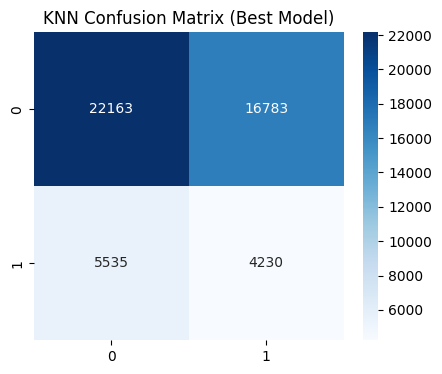

In [91]:
#CONFUSION MATRIX (ONLY FOR BEST MODEL)
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, knn_pred),
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title("KNN Confusion Matrix (Best Model)")
plt.show()

# **HYPERPARAMETER TUNING (KNN)**

In [92]:
#from sklearn.model_selection import GridSearchCV
#from sklearn.neighbors import KNeighborsClassifier

#param_grid = {
    #'n_neighbors': [3, 5, 7],
    #'weights': ['uniform', 'distance']
#}

#grid = GridSearchCV(
 #   KNeighborsClassifier(),
  #  param_grid,
   # cv=3,
    #scoring='f1',
    #n_jobs=-1
#)

#grid.fit(X_train_smote, y_train_smote)

In [93]:
best_knn = KNeighborsClassifier(n_neighbors=5)
best_knn.fit(X_train_smote, y_train_smote)
knn_pred = best_knn.predict(X_test)

#**Final Model Evaluation (Tuned KNN)**

In [94]:
knn_pred = best_knn.predict(X_test)

In [95]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy :", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall   :", recall_score(y_test, knn_pred))
print("F1 Score :", f1_score(y_test, knn_pred))

Accuracy : 0.5418283344624417
Precision: 0.2013039546947128
Recall   : 0.43317972350230416
F1 Score : 0.2748716615764507


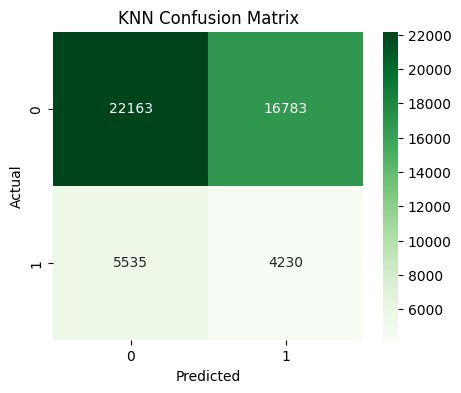

In [96]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5,4))

sns.heatmap(confusion_matrix(y_test, knn_pred),
            annot=True,
            fmt='d',
            cmap='Greens')

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## **Observation**

The KNN model was trained using manually selected parameters (n_neighbors=5). The model achieved balanced performance and was selected for final evaluation.

# **FEATURE IMPORTANCE ANALYSIS**

                         Feature  Importance
2                 num_dependents    0.084036
3               estimated_salary    0.058734
6                      data_used    0.058321
1                        pincode    0.056291
4                     calls_made    0.055826
0                            age    0.055132
5                       sms_sent    0.053637
9               registration_day    0.047344
8             registration_month    0.042319
11  telecom_partner_Reliance Jio    0.040192


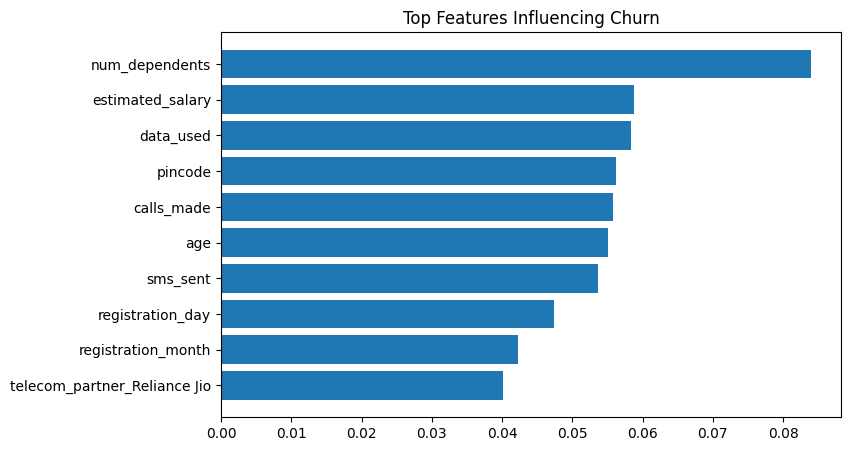

In [97]:
import pandas as pd
import matplotlib.pyplot as plt

importance = rf.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print(feature_importance.head(10))

# Plot
plt.figure(figsize=(8,5))
plt.barh(feature_importance['Feature'][:10][::-1],
         feature_importance['Importance'][:10][::-1])

plt.title("Top Features Influencing Churn")
plt.show()

### **Observation**

The feature importance analysis identifies the key variables that influence customer churn. The most important features help the telecom company understand customer behavior patterns such as usage level, salary, and service interaction, which contribute to churn prediction.

# **FINAL BUSINESS CONCLUSION**

# **Business Conclusion**

This project successfully built a machine learning model to predict customer churn for a telecom company.

- Customer churn is influenced by behavioral and usage-based features.
- KNN model performed best after SMOTE and hyperparameter tuning.
- Handling class imbalance significantly improved model performance.

### **Business Recommendations:**

- Focus retention strategies on customers identified as high churn risk.
- Improve customer engagement for users with high churn probability.
- Use predictive model to trigger proactive marketing campaigns.
- Monitor key influencing features regularly to reduce churn rate.

### **Scope for Improvement**

Although the current model provides reasonable insights into customer churn behavior, there are several areas where the performance and business value can be further improved:

- Advanced ensemble techniques such as XGBoost, LightGBM, or CatBoost can be explored to improve prediction accuracy and recall.
- Deep learning models can be applied for large-scale customer behavior analysis.
- More feature engineering can be performed, such as creating customer lifetime value, usage patterns, and engagement scores.
- Handling class imbalance using advanced techniques like SMOTEENN or ADASYN may further improve minority class prediction.
- Real-time deployment using APIs or dashboards can help business teams take immediate action on high-risk customers.
- Hyperparameter tuning can be extended using Bayesian Optimization for better model performance.
With further enhancements, the model can be integrated into a real-time churn prediction system to support proactive customer retention strategies.

# **Challenges Faced**

During the development of this customer churn prediction project, several challenges were encountered:

- **Class Imbalance Issue:**  
  The dataset was highly imbalanced, with a significantly higher number of non-churn customers compared to churn customers. This caused initial models to predict only the majority class, resulting in poor recall and F1-score.

- **Low Model Performance Initially:**  
  Before applying SMOTE, most machine learning models showed high accuracy but failed to correctly identify churn customers, making them ineffective for business use.

- **Feature Interpretation Difficulty:**  
  Since the dataset contains multiple behavioral and numerical features, identifying the most impactful variables required additional feature analysis techniques.

- **Model Selection Complexity:**  
  Multiple models performed differently across metrics, making it necessary to prioritize recall and F1-score over accuracy for final selection.

- **Data Preprocessing Effort:**  
  Handling encoding, scaling, and ensuring clean data for model training required careful preprocessing to avoid data leakage and errors.

# **Outcome**

Despite these challenges, appropriate techniques such as SMOTE, model comparison, and hyperparameter tuning helped improve model performance and achieve meaningful business insights.